# Base Modeling

### 1. Conectar con Google Drive e importar librerías

In [27]:
%load_ext autoreload
%autoreload 2
import json
import os
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
if IN_COLAB:
  print("Mount Colab")
  from google.colab import drive
  drive.mount('/content/drive')
  !rm -rf vms
  RUTA_DATOS = "/content/drive/My Drive/Datos/Procesado"
else:
  print("Running local")
  RUTA_DATOS = Path.cwd() / ".." / ".." / "data"
  print(RUTA_DATOS)

Running local
c:\Users\Santiago\Documents\Personal\IA\VMS-prediction\notebooks\modeling\..\..\data


In [29]:
if IN_COLAB:  
  !git clone https://github.com/kamimartinez/VMS-prediction.git vms
  def change_branch(branch):
    !git -C vms checkout {branch}
  # change_branch("feat/lstm")
  sys.path.append(os.path.abspath("vms/notebooks"))

In [30]:
if IN_COLAB:
  !ls vms/notebooks

### 2. Cargar el dataset final
Se lee desde `Datos/Procesado`. Si no existe, primero hay que ejecutar `DataPreparation.ipynb` completo.

In [31]:
def load_dataset(file="dataset_final_serie_tiempo.parquet"):
  dataset_final = pd.read_parquet(os.path.join(RUTA_DATOS, file))
  dataset_final["bloque_tiempo"] = pd.to_datetime(dataset_final["bloque_tiempo"])
  dataset_final = dataset_final.sort_values(["bloque_tiempo", "ms"]).reset_index(drop=True)

  print(f"dataset_final: {len(dataset_final):,} bloques x {dataset_final.shape[1]} columnas")
  print(list(dataset_final.columns))
  return dataset_final

### 3. Parámetros

* `USAR_VACAS`: incluye `vacas_activas_dia` como covariable (recomendado: el cambio de prevalencia viene del crecimiento del hato).
* `USAR_CLASS_WEIGHT`: el `balanced` se calcula con la prevalencia de train (≈15 %), que no es la de val/test; por eso va apagado. El umbral se ajusta en validación.
* `VIDA_MEDIA_DIAS`: peso temporal exponencial (los datos recientes pesan más). `None` lo desactiva.

In [32]:
TARGET = "pct_posible_cola"
N_FOLDS = 5
CORTE_COLA = 0.5          # definición del evento: pct_posible_cola > CORTE_COLA
SEED = 42

USAR_VACAS = True
USAR_CLASS_WEIGHT = False
VIDA_MEDIA_DIAS = 180     # None para desactivar

# Normalización de datos

In [ ]:
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = load_dataset()
df = df.sort_values(["ms", "bloque_tiempo"]).reset_index(drop=True)

g = df.groupby("ms")
contiguo = (df["bloque_tiempo"] - g["bloque_tiempo"].shift(1)) == pd.Timedelta("30min")

COLS_ORDENIO = [
    "total_ordenios",
    "duracion_total_min",
    "pct_ocupacion_robot",
    "hubo_ordenios",
]
cols_lag = [c for c in COLS_ORDENIO if c in df.columns]

for c in cols_lag:
    df[f"{c}_anterior"] = g[c].shift(1).where(contiguo)

df["pct_cola_anterior"] = g[TARGET].shift(1).where(contiguo)

# Primera diferencia de las proporciones de etapa de lactancia dentro de cada VMS.
# Solo se conserva el cambio entre bloques contiguos de 30 minutos.
# COLS_PRIMERA_DIFERENCIA = ["pct_alta", "pct_baja", "pct_extendida"]
# for c in COLS_PRIMERA_DIFERENCIA:
#     df[f"{c}_dif1"] = g[c].diff().where(contiguo)

# --- Codificación cíclica (23h está al lado de 0h; domingo al lado de lunes)
df["hora_sin"] = np.sin(2 * np.pi * df["hora"] / 24)
df["hora_cos"] = np.cos(2 * np.pi * df["hora"] / 24)
df["dia_sin"] = np.sin(2 * np.pi * df["dia_semana"] / 7)
df["dia_cos"] = np.cos(2 * np.pi * df["dia_semana"] / 7)

df["cola"] = (df[TARGET] > CORTE_COLA).astype("float32")

# Orden temporal ESTABLE: los 3 VMS comparten timestamp, el desempate por ms evita que el corte parta un bloque
df = df.sort_values(["bloque_tiempo", "ms"], kind="stable").reset_index(drop=True)

df_clean = df.drop(columns=cols_lag).dropna(
    subset=["pct_cola_anterior"] # + [f"{c}_dif1" for c in COLS_PRIMERA_DIFERENCIA]
).copy().reset_index(drop=True)

# drop_first=True: evita colinealidad exacta con el intercepto
df_clean = pd.get_dummies(df_clean, columns=["ms", "temporada"], dtype="float32", drop_first=True)

# vacas_activas_dia se mantiene (se selecciona con USAR_VACAS más adelante)
VARIABLES_MECANICAS = ["bloque_tiempo", "cola", "produccion_promedio", "sin_etapa", "hora", "dia_semana", "vacas_activas_dia"]
VARIABLES_COINTEGRADAS = ["pct_alta", "patadas_totales"] # "pct_fresca", "ordenios_con_lavado", "ordenios_otros_robots", "pct_ocupacion_robot_anterior", "total_ordenios_anterior", "desviaciones_leche_totales", "hubo_lavado", "duracion_total_min_anterior", "pct_cola_anterior", "patadas_totales", "pct_primer_parto"
DROP_COLUMNS = [TARGET] + VARIABLES_MECANICAS  + VARIABLES_COINTEGRADAS # + COLS_PRIMERA_DIFERENCIA
y_all = df_clean["cola"].values
X_full = df_clean.drop(columns=DROP_COLUMNS)
print(X_full.columns)


def construir_preprocesador(X):
    """Escala numéricas (imputa 0 + StandardScaler) y deja las dummies tal cual."""
    dummies = [c for c in X.columns if c.startswith(("ms_", "temporada_"))]
    categoricas = X.select_dtypes(include=["object", "category", "string"]).columns.tolist()
    numericas = [
        c for c in X.select_dtypes(include="number").columns
        if c not in dummies and c != "cola"
    ]
    num_pipeline = Pipeline(
        [
            ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
            ("scaler", StandardScaler()),
        ]
    )
    pre = ColumnTransformer(
        transformers=[
            ("num", num_pipeline, numericas),
            ("bin", "passthrough", dummies),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )
    pre.set_output(transform="pandas")
    return pre


preprocessor = construir_preprocesador(X_full)
# OJO: ya NO se hace fit_transform sobre todo X. El ajuste se hace solo con train en el bloque siguiente.

dataset_final: 179,850 bloques x 24 columnas
['ms', 'bloque_tiempo', 'total_ordenios', 'produccion_promedio', 'duracion_total_min', 'patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado', 'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja', 'pct_extendida', 'hubo_ordenios', 'pct_ocupacion_robot', 'hubo_lavado', 'ordenios_otros_robots', 'hora', 'dia_semana', 'temporada', 'min_desde_alimento', 'vacas_activas_dia', 'sin_etapa', 'pct_posible_cola']
Index(['patadas_totales', 'desviaciones_leche_totales', 'ordenios_con_lavado',
       'pct_primer_parto', 'pct_fresca', 'pct_alta', 'pct_baja',
       'pct_extendida', 'hubo_lavado', 'ordenios_otros_robots',
       'min_desde_alimento', 'total_ordenios_anterior',
       'duracion_total_min_anterior', 'pct_ocupacion_robot_anterior',
       'hubo_ordenios_anterior', 'pct_cola_anterior', 'hora_sin', 'hora_cos',
       'dia_sin', 'dia_cos', 'ms_VMS 2', 'ms_VMS 3', 'temporada_otoño',
       'temporada_primavera', 'temporada_veran

# Separación de train y tests

In [34]:
n = len(X_full)
n_train, n_val = int(n * 0.70), int(n * 0.85)

preprocessor.fit(X_full.iloc[:n_train])                      # solo train
X_all_full = preprocessor.transform(X_full).astype("float32")
feature_names_full = list(X_all_full.columns)
X_all_full = X_all_full.values

# Selección de columnas según USAR_VACAS
sel = [i for i, c in enumerate(feature_names_full) if USAR_VACAS or c != "vacas_activas_dia"]
feature_names = [feature_names_full[i] for i in sel]
X_all = X_all_full[:, sel]

t_obj = np.arange(len(X_all))

train = t_obj < n_train
val = (t_obj >= n_train) & (t_obj < n_val)
test = t_obj >= n_val

X_train, y_train = X_all[train], y_all[train]
X_val, y_val = X_all[val], y_all[val]
X_test, y_test = X_all[test], y_all[test]

print("X_train:", X_train.shape, "| X_val:", X_val.shape, "| X_test:", X_test.shape)
print("pct cola -> train: %.3f | val: %.3f | test: %.3f" % (y_train.mean(), y_val.mean(), y_test.mean()))

fechas = df_clean["bloque_tiempo"].values

splits = {"Train": train, "Val": val, "Test": test}

print("=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===")
for nombre, mascara in splits.items():
    indices_bloque = t_obj[mascara]
    fecha_inicio = np.datetime_as_string(fechas[indices_bloque[0]]).split("T")[0]
    fecha_fin = np.datetime_as_string(fechas[indices_bloque[-1]]).split("T")[0]
    print(f"{nombre:<6} | Inicio: {fecha_inicio} | Fin: {fecha_fin} | Ventanas: {len(indices_bloque)}")

X_train: (125892, 25) | X_val: (26977, 25) | X_test: (26978, 25)
pct cola -> train: 0.147 | val: 0.425 | test: 0.575
=== RANGOS DE FECHAS POR BLOQUE DE VENTANAS ===
Train  | Inicio: 2022-08-01 | Fin: 2024-12-22 | Ventanas: 125892
Val    | Inicio: 2024-12-22 | Fin: 2025-06-27 | Ventanas: 26977
Test   | Inicio: 2025-06-27 | Fin: 2025-12-31 | Ventanas: 26978


# Modelo

In [35]:
if IN_COLAB:
  from modeling.model_base import BaseModel
  from modeling.lr import LogisticRegression
else:
  from model_base import BaseModel
  from lr import LogisticRegression
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from pathlib import Path

model_path = Path.cwd()
model_output_dir = model_path / ".." / ".." / "models" / "logistic-regression"
model_output_dir.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

model_base = LogisticRegression()

model = model_base.compile(input_shape=(X_train.shape[1],))
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26 (104.00 B)

 Trainable params: 26 (104.00 B)

 Non-trainable params: 0 (0.00 B)

In [36]:
def pesos_temporales(fechas_tr, vida_media_dias):
    """Peso exponencial: un dato con `vida_media_dias` de antigüedad pesa la mitad que el más reciente."""
    if vida_media_dias is None:
        return None
    dias = (fechas_tr.max() - fechas_tr) / np.timedelta64(1, "D")
    w = 0.5 ** (dias / vida_media_dias)
    return (w / w.mean()).astype("float32")      # media 1 para no alterar la escala de la loss


callbacks = [
    EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    ModelCheckpoint(
        model_output_dir / "logistic_regresion.keras", monitor="val_loss", save_best_only=True
    ),
]

class_weight = None
if USAR_CLASS_WEIGHT:
    cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
    class_weight = {0: cw[0], 1: cw[1]}
print("class_weight:", class_weight)

sample_weight = pesos_temporales(fechas[train], VIDA_MEDIA_DIAS)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=128,
    class_weight=class_weight,
    sample_weight=sample_weight,
    callbacks=callbacks,
    shuffle=True,
    verbose=1,
)

print("Model Finished")

class_weight: None
Epoch 1/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - accuracy: 0.7388 - auc: 0.6251 - loss: 0.6234 - precision: 0.2167 - recall: 0.2989 - val_accuracy: 0.5819 - val_auc: 0.6172 - val_loss: 0.7056 - val_precision: 0.5503 - val_recall: 0.0939
Epoch 2/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8459 - auc: 0.7555 - loss: 0.4923 - precision: 0.3664 - recall: 0.0700 - val_accuracy: 0.5811 - val_auc: 0.6524 - val_loss: 0.6820 - val_precision: 0.5392 - val_recall: 0.1044
Epoch 3/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8486 - auc: 0.7760 - loss: 0.4763 - precision: 0.3898 - recall: 0.0582 - val_accuracy: 0.5806 - val_auc: 0.6591 - val_loss: 0.6693 - val_precision: 0.5369 - val_recall: 0.1026
Epoch 4/50
984/984 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8498 - auc: 0.7787 - loss: 0.4698 - precision: 0.4022 - recall: 0.0506 - val_accuracy: 0.5814 - val_auc: 0.6623 - val_loss: 0.6624 - val_precision: 0.5470 - val_recall: 0.0927
Epoch 5/50
98

# Evaluación

El umbral **no se fija en 0.5**: se elige en validación maximizando F1. Como F1 depende de la prevalencia, junto a cada resultado se muestra el **F1 trivial** (predecir siempre "hay cola": `2p/(1+p)`) y el **lift** sobre él. Un F1 alto con lift ≈ 0 significa que el modelo no aporta.

In [37]:
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score,
    average_precision_score, precision_recall_curve,
)

def mejor_umbral(y, p):
    """Umbral que maximiza F1 sobre (y, p)."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = int(np.nanargmax(f1[:-1]))
    return float(thr[i]), float(f1[i])

def metricas(y, p, thr):
    y = np.asarray(y).astype(int)
    yhat = (p >= thr).astype(int)
    prev = y.mean()
    f1 = f1_score(y, yhat, zero_division=0)
    f1_triv = 2 * prev / (1 + prev)
    return {
        "Umbral": thr,
        "F1": f1,
        "F1 trivial": f1_triv,
        "Lift F1": f1 - f1_triv,
        "Precision": precision_score(y, yhat, zero_division=0),
        "Recall": recall_score(y, yhat, zero_division=0),
        "ROC-AUC": roc_auc_score(y, p),
        "PR-AUC": average_precision_score(y, p),
        "Prevalencia": prev,
    }

p_val = model.predict(X_val, verbose=0).ravel()
p_test = model.predict(X_test, verbose=0).ravel()

UMBRAL, f1_val_opt = mejor_umbral(y_val, p_val)
print(f"Umbral óptimo en validación: {UMBRAL:.4f} (F1 val = {f1_val_opt:.4f})")

threshold_path = (model_output_dir / "logistic_regresion_threshold.json").resolve()
threshold_path.parent.mkdir(parents=True, exist_ok=True)
threshold_config = {
    "decision_threshold": float(UMBRAL),
    "label_threshold": float(CORTE_COLA),
    "selection_method": "max_f1_validation",
}
with threshold_path.open("w", encoding="utf-8") as threshold_file:
    json.dump(threshold_config, threshold_file, indent=2)
    threshold_file.write("\n")
print(f"Umbral de decisión exportado: {threshold_path}")

tabla = pd.DataFrame(
    {
        "Val  @0.5": metricas(y_val, p_val, 0.5),
        "Val  @umbral": metricas(y_val, p_val, UMBRAL),
        "Test @0.5": metricas(y_test, p_test, 0.5),
        "Test @umbral": metricas(y_test, p_test, UMBRAL),
    }
).T
print(tabla.round(4).to_string())

Umbral óptimo en validación: 0.2095 (F1 val = 0.6710)
Umbral de decisión exportado: C:\Users\Santiago\Documents\Personal\IA\VMS-prediction\models\logistic-regression\logistic_regresion_threshold.json
              Umbral     F1  F1 trivial  Lift F1  Precision  Recall  ROC-AUC  PR-AUC  Prevalencia
Val  @0.5        0.5 0.0589      0.5969   -0.538     0.6079  0.0309   0.6881  0.5598       0.4254
Val  @umbral  0.2095  0.671      0.5969   0.0741     0.5217  0.9401   0.6881  0.5598       0.4254
Test @0.5        0.5 0.2147      0.7304  -0.5157     0.8325  0.1233   0.7615  0.7715       0.5753
Test @umbral  0.2095 0.7907      0.7304   0.0603     0.6854  0.9342   0.7615  0.7715       0.5753


X_test: (26978, 25) | y_test: (26978,)

=== TEST SET CLASSIFICATION METRICS ===
   Metric  Value
 Accuracy 0.7155
Precision 0.6854
   Recall 0.9342
 F1-Score 0.7907
  ROC-AUC 0.7615


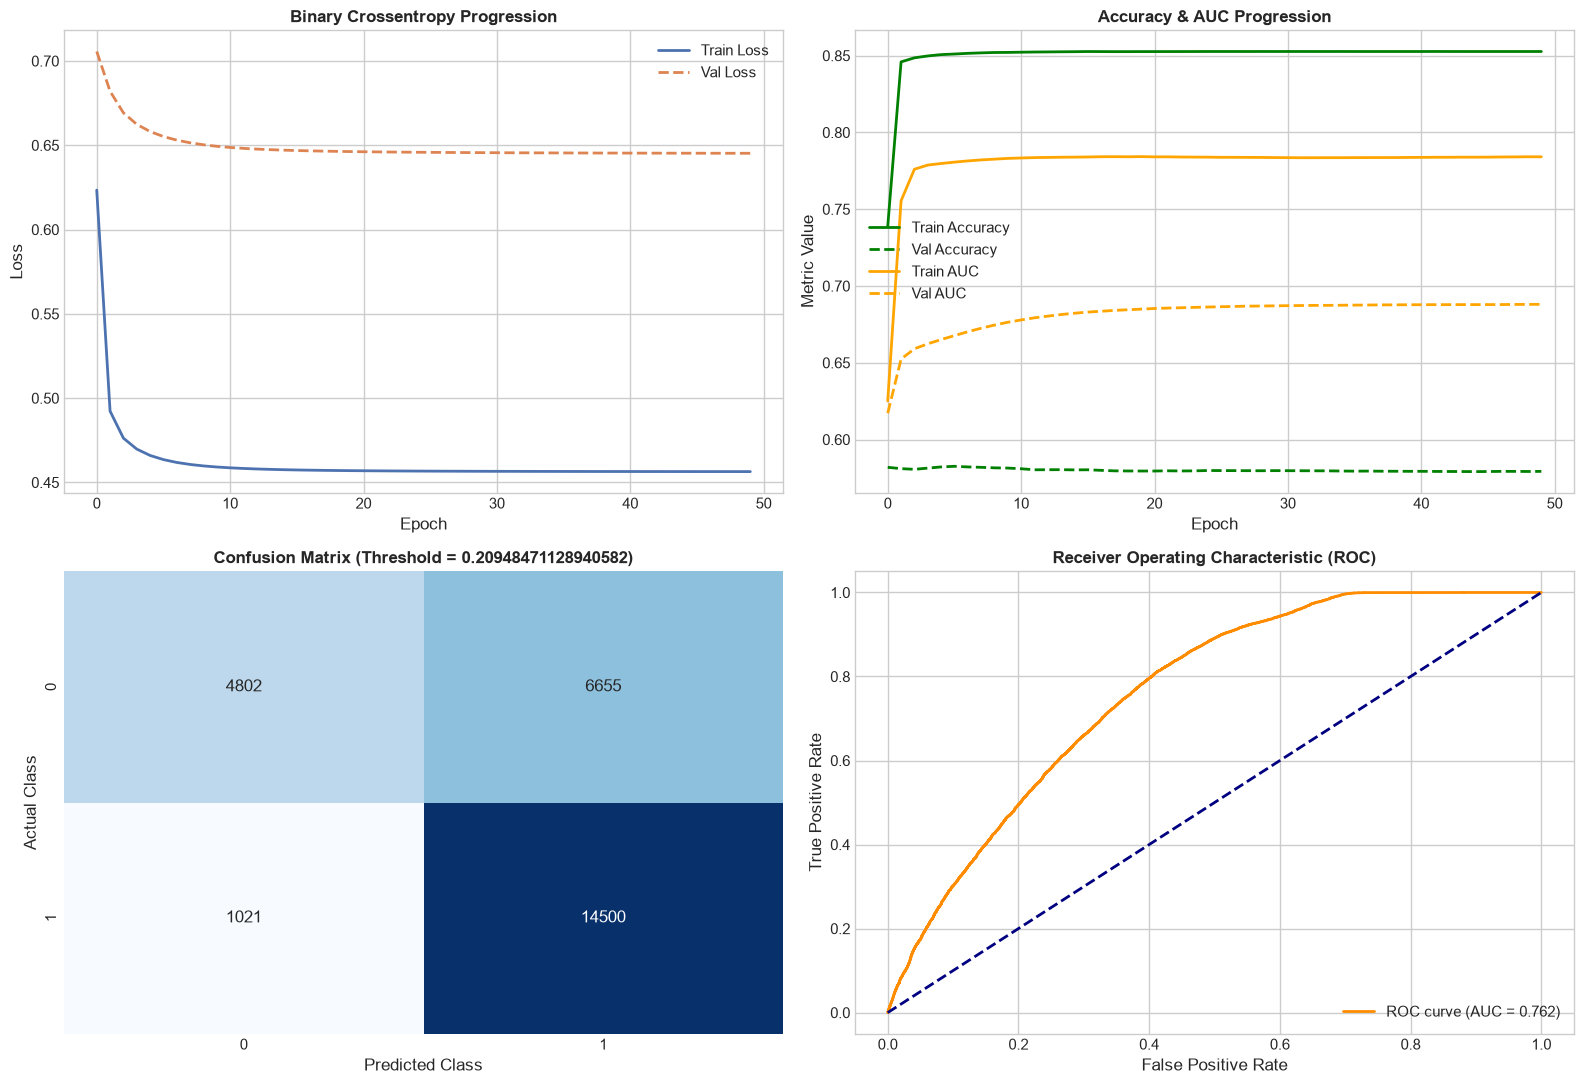

In [38]:
import matplotlib.pyplot as plt

print("X_test:", X_test.shape, "| y_test:", y_test.shape)

df_preds, df_metrics = model_base.evaluate(
    model=history.model,
    history=history,
    X_test=X_test,
    y_test=y_test,
    threshold=UMBRAL,
)

# Estrategias frente al cambio de distribución

Se comparan cuatro configuraciones con el mismo modelo. **La elección se hace con el F1 de validación**; la columna de test solo sirve para confirmar (si eliges mirando test, el test deja de ser independiente).

| Config | Vacas | class_weight | Peso temporal | Umbral |
|---|---|---|---|---|
| A (versión original) | no | balanced | no | 0.5 |
| B | sí | balanced | no | 0.5 |
| C | sí | no | no | val |
| D | sí | no | sí | val |

In [39]:
def entrenar(X_tr, y_tr, X_va, y_va, class_weight=None, sample_weight=None, epochs=50):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    m = LogisticRegression().compile(input_shape=(X_tr.shape[1],))
    m.fit(
        X_tr, y_tr,
        validation_data=(X_va, y_va),
        epochs=epochs, batch_size=128,
        class_weight=class_weight, sample_weight=sample_weight,
        callbacks=[EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)],
        shuffle=True, verbose=0,
    )
    return m


def correr_config(usar_vacas, usar_cw, vida_media, afinar_umbral):
    idx = [i for i, c in enumerate(feature_names_full) if usar_vacas or c != "vacas_activas_dia"]
    Xtr, Xva, Xte = X_all_full[train][:, idx], X_all_full[val][:, idx], X_all_full[test][:, idx]
    cw = None
    if usar_cw:
        w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
        cw = {0: w[0], 1: w[1]}
    m = entrenar(Xtr, y_train, Xva, y_val, cw, pesos_temporales(fechas[train], vida_media))
    pv, pt = m.predict(Xva, verbose=0).ravel(), m.predict(Xte, verbose=0).ravel()
    thr = mejor_umbral(y_val, pv)[0] if afinar_umbral else 0.5
    mv, mt = metricas(y_val, pv, thr), metricas(y_test, pt, thr)
    return {
        "Umbral": thr,
        "F1 val": mv["F1"], "F1 test": mt["F1"],
        "Lift test": mt["Lift F1"],
        "ROC-AUC test": mt["ROC-AUC"], "PR-AUC test": mt["PR-AUC"],
    }

configs = {
    "A original":            dict(usar_vacas=False, usar_cw=True,  vida_media=None,            afinar_umbral=False),
    "B + vacas":             dict(usar_vacas=True,  usar_cw=True,  vida_media=None,            afinar_umbral=False),
    "C + sin cw, umbral val": dict(usar_vacas=True,  usar_cw=False, vida_media=None,            afinar_umbral=True),
    "D + peso temporal":     dict(usar_vacas=True,  usar_cw=False, vida_media=VIDA_MEDIA_DIAS or 180, afinar_umbral=True),
}
comparacion = pd.DataFrame({k: correr_config(**v) for k, v in configs.items()}).T
print(comparacion.round(4).to_string())
print("\nMejor configuración según F1 de VALIDACIÓN:", comparacion["F1 val"].idxmax())

                        Umbral  F1 val  F1 test  Lift test  ROC-AUC test  PR-AUC test
A original                 0.5  0.6707   0.7932     0.0628         0.759       0.7678
B + vacas                  0.5  0.6707   0.7932     0.0628         0.759       0.7678
C + sin cw, umbral val  0.1643  0.6719   0.7943     0.0639        0.7614       0.7714
D + peso temporal       0.2095   0.671   0.7907     0.0603        0.7615       0.7715

Mejor configuración según F1 de VALIDACIÓN: C + sin cw, umbral val


In [40]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

cols_inf = [c for c in X_full.columns if USAR_VACAS or c != "vacas_activas_dia"]
X_inf = X_full[cols_inf]

pre_inf = construir_preprocesador(X_inf)
Z = pre_inf.fit_transform(X_inf).astype("float64")          # escalado con todo el periodo (análisis explicativo)
Zc = sm.add_constant(Z, has_constant="add")
nombres = list(Zc.columns)

grupos_dia = pd.factorize(df_clean["bloque_tiempo"].dt.floor("D"))[0]

logit = sm.Logit(y_all, Zc)
res = logit.fit(disp=0, maxiter=200, cov_type="cluster", cov_kwds={"groups": grupos_dia})
res_ing = logit.fit(disp=0, maxiter=200)                    # errores "ingenuos", solo para comparar

df_stats = pd.DataFrame({
    "Feature": nombres,
    "Coeficiente": res.params.values,
    "Std Error (robusto)": res.bse.values,
    "t (z de Wald)": res.tvalues.values,
    "p-value": res.pvalues.values,
})
df_stats["Significativo (p < 0.05)"] = df_stats["p-value"] < 0.05
df_stats = df_stats.reindex(df_stats["t (z de Wald)"].abs().sort_values(ascending=False).index)

pd.set_option("display.float_format", lambda v: f"{v:.4g}")
print(f"Observaciones: {int(res.nobs):,} | días (clusters): {grupos_dia.max() + 1} | Pseudo R²: {res.prsquared:.4f}\n")
print(df_stats.to_string(index=False))

Observaciones: 179,847 | días (clusters): 1249 | Pseudo R²: 0.2538

                     Feature  Coeficiente  Std Error (robusto)  t (z de Wald)    p-value  Significativo (p < 0.05)
                    pct_baja         1.02              0.01895          53.81          0                      True
                    pct_alta        1.149              0.02149          53.45          0                      True
               pct_extendida       0.6733              0.01271          52.97          0                      True
                       const       -1.768              0.03417         -51.74          0                      True
                  pct_fresca        1.207              0.02423           49.8          0                      True
       ordenios_otros_robots       0.5122              0.01059          48.37          0                      True
             patadas_totales        0.198             0.005982          33.09 3.541e-240                      True
           p

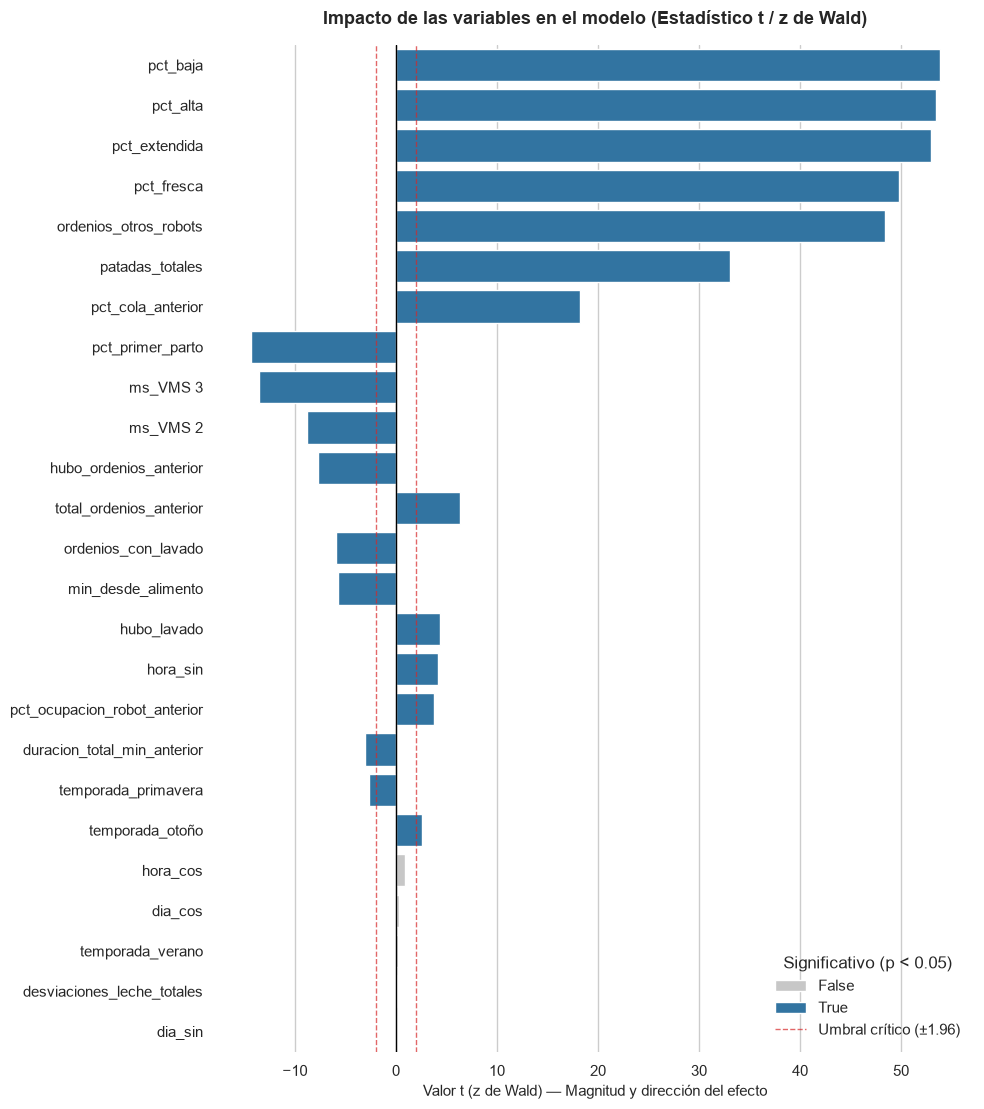

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

df_stats = df_stats[~df_stats["Feature"].isin(["const", "Intercept", "(Intercept)"])].copy()
# 1. Asegurar significancia y ordenar por magnitud (valor absoluto)
df_stats["Significativo (p < 0.05)"] = df_stats["p-value"] < 0.05
df_plot = df_stats.reindex(
    df_stats["t (z de Wald)"].abs().sort_values(ascending=False).index
)

# Nota: Si tus variables están en el índice, descomenta la siguiente línea:
# df_plot = df_plot.reset_index().rename(columns={"index": "Variable"})

# 2. Configurar estilo y tamaño dinámico según el número de variables
plt.figure(figsize=(10, max(5, len(df_plot) * 0.45)))
sns.set_theme(style="whitegrid")

# Paleta: azul intenso para significativas, gris claro para no significativas
paleta = {True: "#1f77b4", False: "#c7c7c7"}

ax = sns.barplot(
    data=df_plot,
    x="t (z de Wald)",
    y="Feature",  # <-- Cambia esto por el nombre de tu columna de variables
    hue="Significativo (p < 0.05)",
    palette=paleta,
    dodge=False,
)

# 3. Líneas de referencia (cero y umbral crítico aproximado de p = 0.05 -> ±1.96)
plt.axvline(0, color="black", linewidth=1)
plt.axvline(1.96, color="#d62728", linestyle="--", linewidth=1, alpha=0.7, label="Umbral crítico (±1.96)")
plt.axvline(-1.96, color="#d62728", linestyle="--", linewidth=1, alpha=0.7)

# 4. Etiquetas y formato limpio
plt.title("Impacto de las variables en el modelo (Estadístico t / z de Wald)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Valor t (z de Wald) — Magnitud y dirección del efecto", fontsize=11)
plt.ylabel("")
plt.legend(title="Significativo (p < 0.05)", loc="lower right")

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

# Pruebas de cointegración y VIF

**VIF (multicolinealidad):** se calcula sobre las variables transformadas y estandarizadas del modelo. Como referencia, VIF < 5 indica poca multicolinealidad; entre 5 y 10 es moderada; mayor a 10 es una señal fuerte de problema.

**Cointegración:** el modelo responde una variable binaria (`cola`), por lo que no tiene sentido probar directamente la cointegración de todos los predictores con esa variable. En su lugar se usa la prueba Engle-Granger con promedios diarios de las variables continuas seleccionadas. La agregación diaria evita que los 179 mil bloques repetidos inflen artificialmente la significancia.

In [42]:
# Factor de inflación de la varianza sobre las variables ya transformadas.
# La constante no se incluye: el VIF mide a los predictores entre sí.
vif = pd.DataFrame({
    "Feature": Z.columns,
    "VIF": [variance_inflation_factor(Z.values, i) for i in range(Z.shape[1])],
})
vif["Diagnóstico"] = np.select(
    [vif["VIF"] < 5, vif["VIF"] < 10],
    ["Bajo", "Moderado"],
    default="Alto",
)
vif = vif.sort_values("VIF", ascending=False).reset_index(drop=True)
print("=== VIF ===")
print(vif.to_string(index=False))

=== VIF ===
                     Feature   VIF Diagnóstico
         ordenios_con_lavado 251.3        Alto
  desviaciones_leche_totales 227.9        Alto
pct_ocupacion_robot_anterior 224.6        Alto
 duracion_total_min_anterior 211.1        Alto
                 hubo_lavado 24.98        Alto
     total_ordenios_anterior 10.45        Alto
          min_desde_alimento 2.501        Bajo
      hubo_ordenios_anterior 2.457        Bajo
           pct_cola_anterior 2.401        Bajo
                    hora_cos  1.89        Bajo
                  pct_fresca 1.625        Bajo
                    hora_sin 1.583        Bajo
             temporada_otoño 1.578        Bajo
                    pct_alta 1.565        Bajo
            temporada_verano 1.554        Bajo
         temporada_primavera  1.51        Bajo
                    pct_baja  1.48        Bajo
       ordenios_otros_robots 1.445        Bajo
                    ms_VMS 3 1.412        Bajo
                    ms_VMS 2 1.399        Bajo
 

In [43]:
from itertools import combinations
from statsmodels.tsa.stattools import adfuller, coint

# Variables económicas continuas que pueden tener comportamiento común en el tiempo.
variables_cointegracion = [
    c for c in [
        "pct_fresca", "pct_alta_dif1", "pct_baja_dif1", "pct_extendida_dif1",
        "pct_primer_parto", "patadas_totales", "pct_cola_anterior",
    ] if c in X_inf.columns
]

serie_diaria = X_inf[variables_cointegracion].copy()
serie_diaria["fecha"] = df_clean["bloque_tiempo"].dt.normalize().values
serie_diaria = serie_diaria.groupby("fecha")[variables_cointegracion].mean().dropna()

print("=== Pruebas de raíz unitaria (ADF) sobre medias diarias ===")
adf_resultados = []
for variable in variables_cointegracion:
    nivel = adfuller(serie_diaria[variable].dropna(), autolag="AIC")
    diferencia = adfuller(serie_diaria[variable].diff().dropna(), autolag="AIC")
    adf_resultados.append({
        "Variable": variable,
        "ADF nivel": nivel[0],
        "p nivel": nivel[1],
        "Nivel estacionario (p < 0.05)": nivel[1] < 0.05,
        "ADF diferencia": diferencia[0],
        "p diferencia": diferencia[1],
        "Diferencia estacionaria (p < 0.05)": diferencia[1] < 0.05,
    })
print(pd.DataFrame(adf_resultados).round(6).to_string(index=False))

pares = list(combinations(variables_cointegracion, 2))
cointegracion = []
for x, y in pares:
	estadistico, p_valor, _ = coint(
        serie_diaria[x].values,
        serie_diaria[y].values,
        trend="c",
        autolag="AIC",
    )

	cointegracion.append({
        "Variable 1": x,
        "Variable 2": y,
        "Estadístico Engle-Granger": estadistico,
        "p-valor": p_valor,
        "p-valor Bonferroni": min(p_valor * len(pares), 1.0),
        "Cointegradas (p < 0.05)": p_valor < 0.05,
    })

df_cointegracion = pd.DataFrame(cointegracion).sort_values("p-valor")
print("\n=== Cointegración Engle-Granger por pares ===")
print(f"Observaciones diarias: {len(serie_diaria):,} | Pares evaluados: {len(pares)}")
print(df_cointegracion.round(6).to_string(index=False))

=== Pruebas de raíz unitaria (ADF) sobre medias diarias ===


C:\Users\Santiago\AppData\Local\Temp\ipykernel_45496\1581939756.py:19: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  nivel = adfuller(serie_diaria[variable].dropna(), autolag="AIC")
C:\Users\Santiago\AppData\Local\Temp\ipykernel_45496\1581939756.py:20: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  diferencia = adfuller(serie_diaria[variable].diff().dropna(), autolag="AIC"

         Variable  ADF nivel  p nivel  Nivel estacionario (p < 0.05)  ADF diferencia  p diferencia  Diferencia estacionaria (p < 0.05)
       pct_fresca     -3.204  0.01976                           True          -18.66             0                                True
 pct_primer_parto      -4.48 0.000214                           True          -15.29             0                                True
  patadas_totales     -1.484   0.5412                          False           -11.1             0                                True
pct_cola_anterior     0.8354   0.9922                          False          -11.61             0                                True

=== Cointegración Engle-Granger por pares ===
Observaciones diarias: 1,249 | Pares evaluados: 6
      Variable 1        Variable 2  Estadístico Engle-Granger  p-valor  p-valor Bonferroni  Cointegradas (p < 0.05)
 patadas_totales pct_cola_anterior                     -7.557        0                   0                     T